# **Air University Multan Campus**<br>

**LAB 8 Task<br>**

**Subject Name & Code:** SE425 Data Mining<br>
**Department:** Computer Science<br>
**Program:** BS Software Engineering<br>
**Semester:** 7 Fall 2026<br>
**Instructor:** Fazle Hanan<br>
**Date & Week:** 21 October 2026 & Week 7<br>
**Lab:** B216<br>

### Student Details

Save this notebook as `RegID_Name_Lab8Task.ipynb` before you submit it.

**Registration ID:** 233670

**Name:** Sidra Ghulam Hussain


Complete the 4 tasks below. They follow Parts 1 and 2 of the Main Lab notebook: PCA (Tasks 8.1 and 8.2) and attribute subset selection (Tasks 8.3 and 8.4). Write your code under each `# TODO` line and run the cell. No expected output is given — read each task carefully and check your own results. Run the tasks in order: later tasks use the variables created in earlier tasks. Do not load any file other than the provided `pk_weather_2022.csv`. Marking criteria are in the Lab 8 Task Handout rubric.

### About the data

Real Pakistani weather data from the NASA Prediction of Worldwide Energy Resources (POWER) Project, Daily API version 2.10.0 (https://power.larc.nasa.gov/), downloaded on 20 October 2026. The AWS Registry of Open Data lists the NASA POWER data as CC BY 4.0 with no restrictions on use (https://registry.opendata.aws/nasa-power/).

`pk_weather_2022.csv` has the daily weather of four cities for the year 2022 (365 days each, 1460 rows): Islamabad, Peshawar, Quetta and Hyderabad. These are different cities and a different year from the Main Lab. The columns are the same as in the Main Lab: `date`, `city`, and 12 numeric attributes: `T2M`, `T2M_MAX`, `T2M_MIN` and `T2MDEW` (air temperature, maximum, minimum and dew point at 2 m, °C), `TS` (earth skin temperature, °C), `RH2M` (relative humidity, %), `QV2M` (specific humidity, g/kg), `PRECTOTCORR` (precipitation, mm/day), `WS10M` (wind speed at 10 m, m/s), `PS` (surface pressure, kPa), `ALLSKY_SFC_SW_DWN` and `CLRSKY_SFC_SW_DWN` (solar energy reaching the ground under the actual sky and under a clear sky, MJ/m²/day).

The values are satellite and model estimates for a grid cell around each city, not readings from one weather station. Changes made for this lab: the downloaded JSON was turned into a table and the city and date columns were added; nothing else was altered. No value is missing.

In [1]:
# Setup cell — run this first. Do not modify.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, VarianceThreshold, f_classif

# In Google Colab: when the upload window opens, choose pk_weather_2022.csv.
# On your own computer (Jupyter / Anaconda): keep the file in the notebook's folder; the upload step is skipped.
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

weather_df = pd.read_csv("pk_weather_2022.csv")
print(weather_df.shape)
weather_df.head()

Saving pk_weather_2022.csv to pk_weather_2022.csv
(1460, 14)


,date,city,T2M,T2M_MAX,T2M_MIN,T2MDEW,TS,RH2M,QV2M,PRECTOTCORR,WS10M,PS,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN
0,2022-01-01,Islamabad,10.59,15.89,6.80,1.23,8.24,54.45,4.40,0.02,1.95,95.78,5.95,11.60
1,2022-01-02,Islamabad,10.74,18.13,6.85,2.32,8.47,58.29,4.74,0.00,2.35,95.65,10.72,11.79
2,2022-01-03,Islamabad,11.36,17.11,7.94,4.82,9.95,65.45,5.68,0.45,2.82,95.50,4.29,12.07
3,2022-01-04,Islamabad,9.79,12.89,7.61,7.86,9.27,88.03,6.95,9.97,3.06,95.54,2.61,9.71
4,2022-01-05,Islamabad,8.27,10.75,5.17,6.59,7.45,89.10,6.41,40.73,1.94,95.24,1.65,10.41


### Task 8.1 — PCA: standardize, fit and choose the number of components (25 marks)

1. Create `city_labels` (the `city` column) and `X` (the table of the 12 weather attributes: all columns except `date` and `city`). Print the shape of `X`.
2. Standardize `X` with `StandardScaler` and store the result as `X_scaled`. Print the largest absolute column mean, and the smallest and the largest column standard deviation (`ddof=0`) of `X_scaled`, rounded to 6 decimal places.
3. Fit `PCA()` (all components) on `X_scaled`. Store the explained variance ratios as `variance_ratio` and their cumulative sum as `cumulative_ratio`. Print the first four ratios and the first five cumulative ratios, rounded to 4 decimal places.
4. Using `cumulative_ratio` (find the answers with code), print the smallest number of components whose cumulative ratio is above 0.90 and the smallest number whose cumulative ratio is above 0.95.
5. Draw a scree plot: bars for `variance_ratio`, a line with markers for `cumulative_ratio`, a dashed horizontal line at 0.90, labelled axes, a title and a legend.

Shape of X: (1460, 12)
Largest absolute column mean: 0.0
Smallest column std: 1.0
Largest column std:  1.0
First four ratios: [0.498  0.2389 0.0979 0.0757]
First five cumulative ratios: [0.498  0.7369 0.8348 0.9105 0.9694]
Components needed for more than 90% of the variance: 4
Components needed for more than 95% of the variance: 5


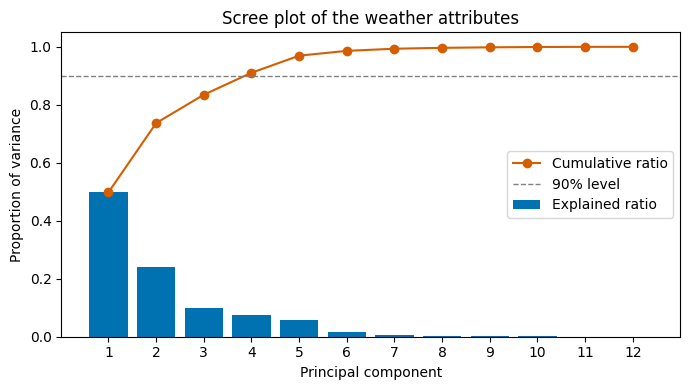

In [2]:
# TODO: build X and city_labels, standardize, fit PCA on all components, find the number of components for 90% and 95%, and draw the scree plot

# class label and the 12 weather attributes
city_labels = weather_df["city"]
X = weather_df.drop(columns=["date", "city"])
print("Shape of X:", X.shape)

# Standardize so every attribute counts equally in PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Check: means should be 0 and standard deviations should be 1
print("Largest absolute column mean:", round(np.abs(X_scaled.mean(axis=0)).max(), 6))
print("Smallest column std:", round(X_scaled.std(axis=0, ddof=0).min(), 6))
print("Largest column std: ", round(X_scaled.std(axis=0, ddof=0).max(), 6))

# Fit PCA with all components
pca_all = PCA()
pca_all.fit(X_scaled)

# Explained variance ratio of each component and its cumulative sum
variance_ratio = pca_all.explained_variance_ratio_
cumulative_ratio = np.cumsum(variance_ratio)
print("First four ratios:", variance_ratio[:4].round(4))
print("First five cumulative ratios:", cumulative_ratio[:5].round(4))

# Smallest number of components above 90% and above 95% (found with code)
n_components_90 = int(np.argmax(cumulative_ratio > 0.90) + 1)
n_components_95 = int(np.argmax(cumulative_ratio > 0.95) + 1)
print("Components needed for more than 90% of the variance:", n_components_90)
print("Components needed for more than 95% of the variance:", n_components_95)

# Scree plot: bars for each component, line for the cumulative ratio
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(1, len(variance_ratio) + 1), variance_ratio, color="#0072B2", label="Explained ratio")
ax.plot(range(1, len(variance_ratio) + 1), cumulative_ratio, color="#D55E00", marker="o", label="Cumulative ratio")
ax.axhline(0.90, color="gray", linestyle="--", linewidth=1, label="90% level")
ax.set_xlabel("Principal component")
ax.set_ylabel("Proportion of variance")
ax.set_title("Scree plot of the weather attributes")
ax.set_xticks(range(1, len(variance_ratio) + 1))
ax.legend(loc="center right")
plt.tight_layout()
plt.show()

### Task 8.2 — PCA: reduce the data and read the components (25 marks)

Using `X_scaled`, `X`, and `city_labels` from Task 8.1:
1. Create `pca_90` with `PCA(n_components=0.90, svd_solver="full")` and store `pca_90.fit_transform(X_scaled)` as `X_reduced`. Print the shape before and after the reduction, the number of components kept, the variance kept (rounded to 4 decimal places), and the percentage of attributes removed (rounded to 1 decimal place).
2. Build a table `loadings` with one row per attribute and the columns `PC1`, `PC2` and `PC3` from `pca_90.components_`. For `PC2` and for `PC3`, print the names of the three attributes with the largest absolute loading, largest first (use code, do not type the names).
3. Draw a scatter plot of `PC1` (x axis) against `PC2` (y axis) with one colour for each of the four cities, a legend, labelled axes and a title.
4. Print the average `PC1` and the average `PC2` of each city, rounded to 3 decimal places.

Before reduction: (1460, 12)
After reduction:  (1460, 4)
Components kept:  4
Variance kept:    0.9105
Attributes removed (%): 66.7


,PC1,PC2,PC3
T2M,0.401,-0.060,0.055
T2M_MAX,0.381,-0.157,0.146
T2M_MIN,0.401,0.049,0.001
T2MDEW,0.314,0.353,-0.033
TS,0.401,-0.066,0.030
RH2M,0.016,0.543,-0.146
QV2M,0.307,0.337,-0.174
PRECTOTCORR,0.043,0.315,-0.475
WS10M,0.128,-0.027,0.247
PS,0.156,0.250,0.682


PC2 -> ['RH2M', 'ALLSKY_SFC_SW_DWN', 'T2MDEW']
PC3 -> ['PS', 'PRECTOTCORR', 'CLRSKY_SFC_SW_DWN']


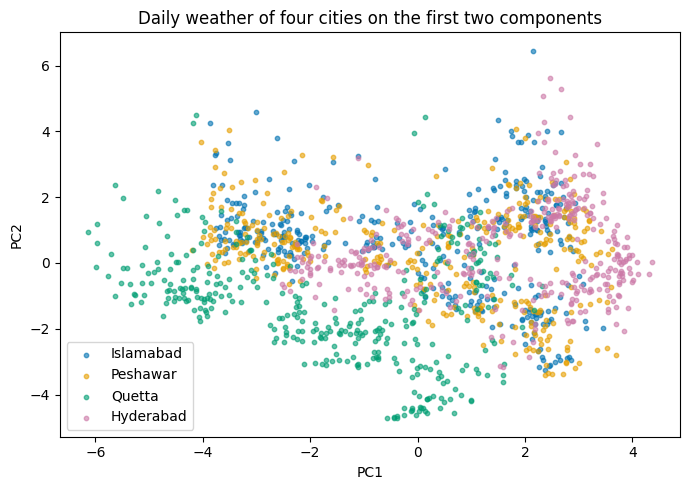

,PC1,PC2
Hyderabad,1.524,0.396
Islamabad,0.042,0.633
Peshawar,0.094,0.272
Quetta,-1.659,-1.300


In [3]:
# TODO: reduce X_scaled with PCA(n_components=0.90), build the loadings table, plot PC1 against PC2 by city, and print the city averages

# keep enough components for more than 90% of the variance
pca_90 = PCA(n_components=0.90, svd_solver="full")
X_reduced = pca_90.fit_transform(X_scaled)

print("Before reduction:", X_scaled.shape)
print("After reduction: ", X_reduced.shape)
print("Components kept: ", pca_90.n_components_)
print("Variance kept:   ", round(pca_90.explained_variance_ratio_.sum(), 4))
print("Attributes removed (%):", round((1 - X_reduced.shape[1] / X_scaled.shape[1]) * 100, 1))

# Loadings of the first three components (one row per attribute)
loadings = pd.DataFrame(
    pca_90.components_[:3].T,
    index=X.columns,
    columns=["PC1", "PC2", "PC3"],
)
display(loadings.round(3))

# Three attributes with the largest absolute loading for PC2 and PC3
for component in ["PC2", "PC3"]:
    top_three = loadings[component].abs().sort_values(ascending=False).head(3).index.tolist()
    print(component, "->", top_three)

# Scatter plot of PC1 against PC2, one colour per city
city_colours = {"Islamabad": "#0072B2", "Peshawar": "#E69F00", "Quetta": "#009E73", "Hyderabad": "#CC79A7"}
fig, ax = plt.subplots(figsize=(7, 5))
for city, colour in city_colours.items():
    rows = (city_labels == city).to_numpy()
    ax.scatter(X_reduced[rows, 0], X_reduced[rows, 1], s=10, alpha=0.6, color=colour, label=city)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Daily weather of four cities on the first two components")
ax.legend()
plt.tight_layout()
plt.show()

# Average PC1 and PC2 of each city
pc_scores = pd.DataFrame(X_reduced[:, :2], columns=["PC1", "PC2"])
display(pc_scores.groupby(city_labels.to_numpy()).mean().round(3))

### Task 8.3 — Attribute subset selection: variance threshold (25 marks)

Using `X` from Task 8.1:
1. Scale every attribute of `X` to the range 0 to 1 with `MinMaxScaler` and store the result as the table `X_minmax` (same column names as `X`). Print the variance (`ddof=0`) of every attribute of `X_minmax`, smallest first, rounded to 5 decimal places.
2. Apply `VarianceThreshold(threshold=0.035)` to `X_minmax`. Print the shape before and after, and the names of the removed attributes and of the kept attributes (find the names with `get_support()`, do not type them).
3. Print the number of removed attributes, the largest variance among the removed attributes and the smallest variance among the kept attributes, rounded to 5 decimal places.

In [4]:
# TODO: min-max scale X, print the variances, apply VarianceThreshold(0.035), and print the removed and kept attributes with their variance limits

# scale every attribute to 0-1 so the variances can be compared
X_minmax = pd.DataFrame(MinMaxScaler().fit_transform(X), columns=X.columns)

# Variance of every scaled attribute, smallest first
minmax_variance = X_minmax.var(ddof=0).sort_values()
print("Variance of every attribute (smallest first):")
display(minmax_variance.round(5))

# Keep only attributes whose variance is above 0.035
variance_selector = VarianceThreshold(threshold=0.035)
X_variance_kept = variance_selector.fit_transform(X_minmax)

# get_support() is True for every kept attribute
kept_mask = variance_selector.get_support()
kept_by_variance = X.columns[kept_mask].tolist()
removed_by_variance = X.columns[~kept_mask].tolist()

print("Before:", X_minmax.shape, " After:", X_variance_kept.shape)
print("Removed:", removed_by_variance)
print("Kept:   ", kept_by_variance)

print("Number of removed attributes:", len(removed_by_variance))
print("Largest variance among removed:", round(minmax_variance[removed_by_variance].max(), 5))
print("Smallest variance among kept:  ", round(minmax_variance[kept_by_variance].min(), 5))

Variance of every attribute (smallest first):


,0
PRECTOTCORR,0.00790
WS10M,0.02889
T2M_MAX,0.03241
T2M,0.04081
ALLSKY_SFC_SW_DWN,0.04208
TS,0.04463
T2M_MIN,0.04713
CLRSKY_SFC_SW_DWN,0.04854
RH2M,0.05009
T2MDEW,0.05395


Before: (1460, 12)  After: (1460, 9)
Removed: ['T2M_MAX', 'PRECTOTCORR', 'WS10M']
Kept:    ['T2M', 'T2M_MIN', 'T2MDEW', 'TS', 'RH2M', 'QV2M', 'PS', 'ALLSKY_SFC_SW_DWN', 'CLRSKY_SFC_SW_DWN']
Number of removed attributes: 3
Largest variance among removed: 0.03241
Smallest variance among kept:   0.04081


### Task 8.4 — Attribute subset selection: the k best attributes (25 marks)

Using `X`, `city_labels` and `removed_by_variance` from the earlier tasks:
1. Apply `SelectKBest` with `f_classif` and `k=4` to `X` with `city_labels` as the class label and store the result as `X_k_best`. Print the shape before and after.
2. Store the F-score of every attribute as a Series called `f_scores`, indexed by the attribute names and sorted from the highest to the lowest score, and print it rounded to 2 decimal places.
3. Print the names of the 4 selected attributes (use `get_support()`; do not type the names).
4. Print the selected attributes that were removed by the variance threshold in Task 8.3.
5. Print the F-score of the lowest-scoring selected attribute and the F-score of the highest-scoring attribute that was not selected, rounded to 2 decimal places.

In [5]:
# TODO: select the 4 best attributes with SelectKBest(f_classif), print the scores and the selected names, and compare them with the variance-threshold result

# select the 4 best attributes for the city label
k_best_selector = SelectKBest(score_func=f_classif, k=4)
X_k_best = k_best_selector.fit_transform(X, city_labels)
print("Before:", X.shape, " After:", X_k_best.shape)

# F-score of every attribute, highest first
f_scores = pd.Series(k_best_selector.scores_, index=X.columns).sort_values(ascending=False)
print("F-scores:")
display(f_scores.round(2))

# Names of the selected attributes
selected_by_k_best = X.columns[k_best_selector.get_support()].tolist()
print("Selected:", selected_by_k_best)

# Selected attributes that the variance threshold had removed in Task 8.3
print("Selected but removed by the variance threshold:",
      [c for c in selected_by_k_best if c in removed_by_variance])

# Lowest selected score and highest score among the attributes that were not selected
not_selected_scores = f_scores.drop(selected_by_k_best)
print("Lowest F-score among selected:", round(f_scores[selected_by_k_best].min(), 2))
print("Highest F-score among not selected:", round(not_selected_scores.max(), 2))

Before: (1460, 12)  After: (1460, 4)
F-scores:


,0
PS,65872.35
WS10M,289.43
T2MDEW,195.75
T2M_MIN,138.81
T2M,128.70
T2M_MAX,127.09
TS,113.25
QV2M,86.79
RH2M,38.32
ALLSKY_SFC_SW_DWN,25.69


Selected: ['T2M_MIN', 'T2MDEW', 'WS10M', 'PS']
Selected but removed by the variance threshold: ['WS10M']
Lowest F-score among selected: 138.81
Highest F-score among not selected: 128.7
